# Neural content recommendation without behaviour data

This notebook reproduces the main EDA, loads the evaluated model outputs, and explains the cold-start proxy experiment. The source catalog contains title metadata but no viewers, impressions, watches, or per-user ratings.

## 1. Setup and reproducibility

Set `MOVIES_CSV` and `TV_CSV` to use local files. If they are absent, the notebook downloads the two public assignment files.

In [1]:
from pathlib import Path
import json
import os
import sys
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

SEED = 42
np.random.seed(SEED)

PROJECT = Path.cwd()
if PROJECT.name == 'notebooks':
    PROJECT = PROJECT.parent
sys.path.insert(0, str(PROJECT / 'src'))

from recommender.data import CORE_METADATA, build_eda_summary, load_and_clean_catalog

DATA_DIR = PROJECT / 'data' / 'raw'
DATA_DIR.mkdir(parents=True, exist_ok=True)
MOVIES_URL = 'https://raw.githubusercontent.com/pimphornm-pim/DSAssignmentDataSet/main/netflix_movies_detailed_up_to_2025.csv'
TV_URL = 'https://raw.githubusercontent.com/pimphornm-pim/DSAssignmentDataSet/main/netflix_tv_shows_detailed_up_to_2025.csv'

movies_path = Path(os.environ.get('MOVIES_CSV', DATA_DIR / 'netflix_movies_detailed_up_to_2025.csv'))
tv_path = Path(os.environ.get('TV_CSV', DATA_DIR / 'netflix_tv_shows_detailed_up_to_2025.csv'))
for path, url in [(movies_path, MOVIES_URL), (tv_path, TV_URL)]:
    if not path.exists():
        print(f'Downloading {path.name}')
        urllib.request.urlretrieve(url, path)

print('Project:', PROJECT)
print('Movies:', movies_path)
print('TV:', tv_path)

Project: /Users/kittituchwongwatchrapaiboon/Documents/Codex/2026-11-11/i/outputs/telecom_recommender_assignment
Movies: /Users/kittituchwongwatchrapaiboon/Documents/Codex/2026-11-11/i/work/dataset/movies.csv
TV: /Users/kittituchwongwatchrapaiboon/Documents/Codex/2026-11-11/i/work/dataset/tv.csv


## 2. Load, clean, and validate item identity

The cleaning layer creates a composite movie/TV item key, resolves duplicate IDs by metadata completeness, canonicalizes the two genre taxonomies, and treats zero-vote ratings as unobserved.

In [2]:
catalog = load_and_clean_catalog(str(movies_path), str(tv_path))
summary = build_eda_summary(catalog)

overview = pd.Series({
    'Rows after deduplication': summary['rows_after_deduplication'],
    'Movies': summary['movies'],
    'TV shows': summary['tv_shows'],
    'Zero-vote titles': summary['zero_vote_items'],
    'Titles with fewer than 20 votes': summary['low_vote_items_lt_20'],
    'Movie duration missing (%)': summary['movie_duration_missing_pct'],
    'date_added year equals release_year (%)': summary['date_year_equals_release_year_pct'],
}, name='value').to_frame()
display(overview)

,value
Rows after deduplication,31991.0
Movies,16000.0
TV shows,15991.0
Zero-vote titles,4560.0
Titles with fewer than 20 votes,13620.0
Movie duration missing (%),100.0
date_added year equals release_year (%),100.0


### EDA finding: metadata quality differs sharply by content type

TV rows have much weaker director and description coverage. Model comparisons therefore need separate movie/TV and missingness slices.

,director,cast,country,genres,description
type,,,,,
Movie,0.82,1.27,2.91,0.67,0.82
TV Show,68.54,7.23,11.23,6.08,20.03


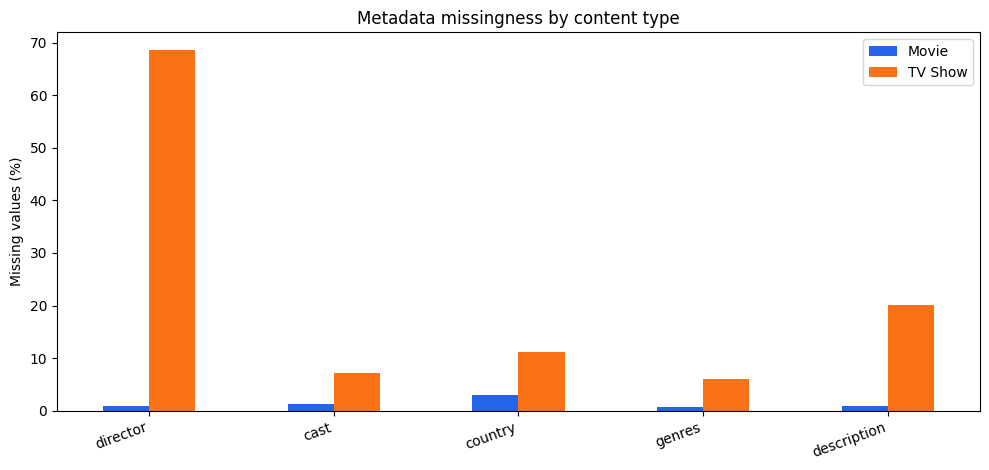

In [3]:
missing = catalog.groupby('type')[CORE_METADATA].apply(lambda x: x.isna().mean() * 100)
display(missing.round(2))
ax = missing.T.plot(kind='bar', figsize=(10, 4.8), color=['#2563eb', '#f97316'])
ax.set(title='Metadata missingness by content type', ylabel='Missing values (%)', xlabel='')
ax.legend(title='')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

### EDA finding: the catalog is uniformly sampled by year

The source includes exactly 1,000 rows per type and year before duplicate removal. This supports a temporal cold-start split, but it does not support claims about Netflix catalog growth.

type,Movie,TV Show
release_year,,
2021,1000,1000
2022,1000,1000
2023,1000,1000
2024,1000,1000
2025,1000,991


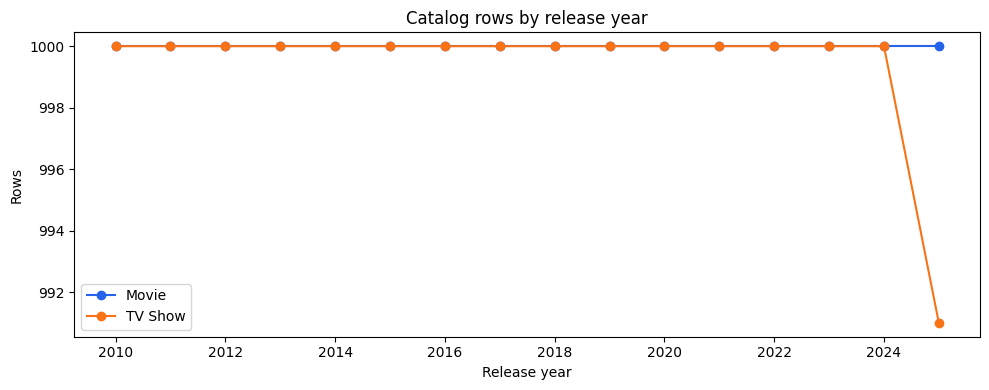

In [4]:
year_counts = catalog.groupby(['release_year', 'type']).size().unstack(fill_value=0)
display(year_counts.tail())
ax = year_counts.plot(figsize=(10, 4), marker='o', color=['#2563eb', '#f97316'])
ax.set(title='Catalog rows by release year', ylabel='Rows', xlabel='Release year')
ax.legend(title='')
plt.tight_layout()
plt.show()

## 3. Experiment design

- Training period: 2010–2023
- Validation period: 2024
- Test candidates: 1,991 deduplicated titles released in 2025
- Evaluation: 500 synthetic cold-start episodes with three related pre-2025 seed titles
- Baselines: popularity, TF-IDF cosine similarity, and SVD similarity
- Deep model: a 128-dimensional PyTorch projection network trained with triplet metric learning

The labels measure metadata consistency. They do not estimate watch lift or customer satisfaction.

## 4. Load the completed comparison

Set `RUN_TRAINING = True` to rerun the complete pipeline. The checked-in artifacts use seed 42 and 15 neural-training epochs.

,model,recall@10,ndcg@10,mrr@10,mean_rank,median_rank,catalog_coverage@10,intra_list_diversity@10
0,popularity,0.006,0.004,0.003,909.376,892.5,0.005,0.890
1,tfidf,0.366,0.178,0.122,87.828,22.5,0.637,0.663
2,svd,0.340,0.185,0.139,96.234,24.0,0.629,0.598
3,neural,0.468,0.261,0.198,60.290,13.0,0.621,0.657
4,neural_mmr,0.478,0.270,0.206,60.020,12.0,0.668,0.672


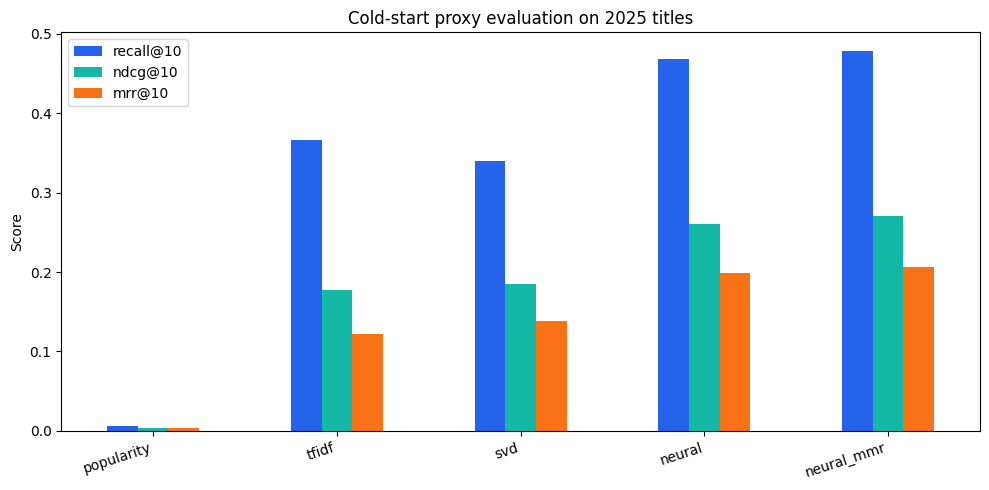

In [5]:
RUN_TRAINING = False
if RUN_TRAINING:
    import subprocess
    subprocess.run([
        sys.executable, str(PROJECT / 'run_experiment.py'),
        '--movies', str(movies_path), '--tv', str(tv_path),
        '--output', str(PROJECT / 'artifacts'),
        '--episodes', '500', '--epochs', '15',
    ], check=True)

metrics = pd.read_csv(PROJECT / 'artifacts' / 'model_metrics.csv')
display(metrics.round(3))

ax = metrics.set_index('model')[['recall@10', 'ndcg@10', 'mrr@10']].plot(
    kind='bar', figsize=(10, 5), color=['#2563eb', '#14b8a6', '#f97316']
)
ax.set(title='Cold-start proxy evaluation on 2025 titles', ylabel='Score', xlabel='')
plt.xticks(rotation=18, ha='right')
plt.tight_layout()
plt.show()

In [6]:
tfidf = metrics.set_index('model').loc['tfidf']
neural_mmr = metrics.set_index('model').loc['neural_mmr']
improvements = pd.Series({
    'Recall@10 relative improvement': neural_mmr['recall@10'] / tfidf['recall@10'] - 1,
    'NDCG@10 relative improvement': neural_mmr['ndcg@10'] / tfidf['ndcg@10'] - 1,
    'MRR@10 relative improvement': neural_mmr['mrr@10'] / tfidf['mrr@10'] - 1,
})
display(improvements.map(lambda value: f'{value:.1%}').to_frame('improvement'))

,improvement
Recall@10 relative improvement,30.6%
NDCG@10 relative improvement,51.8%
MRR@10 relative improvement,69.6%


## 5. Qualitative recommendation audit

Named personas make model failure modes visible. Title collisions are resolved by choosing the most-voted exact-title match.

In [7]:
samples = pd.read_csv(PROJECT / 'artifacts' / 'sample_recommendations.csv')
display(samples[['persona', 'seed_titles', 'rank', 'recommended_title', 'type', 'release_year', 'shared_genres']])

,persona,seed_titles,rank,recommended_title,type,release_year,shared_genres
0,Mind-bending science fiction,Inception | Black Mirror | Stranger Things,1,NEXT,TV Show,2020,"Drama, Fantasy, Science Fiction"
1,Mind-bending science fiction,Inception | Black Mirror | Stranger Things,2,Camelot,TV Show,2011,"Drama, Fantasy, Science Fiction"
2,Mind-bending science fiction,Inception | Black Mirror | Stranger Things,3,The Underground Railroad,TV Show,2021,"Drama, Fantasy, Science Fiction"
3,Mind-bending science fiction,Inception | Black Mirror | Stranger Things,4,The Terror,TV Show,2018,"Drama, Fantasy, Mystery, Science Fiction"
4,Mind-bending science fiction,Inception | Black Mirror | Stranger Things,5,Don't Look Deeper,TV Show,2020,"Drama, Fantasy, Science Fiction"
5,Korean drama and suspense,Crash Landing on You | Squid Game,1,Mine,TV Show,2021,"Drama, Mystery"
6,Korean drama and suspense,Crash Landing on You | Squid Game,2,Fashion King,TV Show,2012,Drama
7,Korean drama and suspense,Crash Landing on You | Squid Game,3,The Uncanny Counter,TV Show,2020,"Action, Adventure, Drama, Mystery"
8,Korean drama and suspense,Crash Landing on You | Squid Game,4,Parasyte: The Grey,TV Show,2024,"Action, Adventure, Drama"
9,Korean drama and suspense,Crash Landing on You | Squid Game,5,KBS Drama Special,TV Show,2010,Drama


## 6. Conclusions and production boundary

The neural + MMR model leads the proxy test with Recall@10 of 0.478 and NDCG@10 of 0.270. Relative to TF-IDF, the gains are 30.6% and 51.8%. MMR increases catalog coverage from 0.621 to 0.668, but the diversity increase is only 2.2%, so the second hypothesis remains only partially supported.

A telecom production model needs logged impressions, starts, completion, skips, searches, entitlement rules, and content availability. Those signals would support a learned user tower and a separate ranking stage.